<a href="https://colab.research.google.com/github/vatsalsadhu10-maximus/telecom-customer-segmentation/blob/main/customer_clustering_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Customer Segmentation and Churn Analysis

**ACS internship | Telecommunications customer analytics | K-means clustering**

This notebook explains the analysis in `clustering.py`, illustrates the saved results and enables reproducibility. It does **not** use churn labels to create clusters; churn is examined **after** segmentation. No individual customer records are displayed or committed.

**Business question:** Can customer tenure, service configuration, contract type and monthly charges identify useful segments for customer retention planning?

In [ ]:

import os
import subprocess

repo = "https://github.com/vatsalsadhu10-maximus/telecom-customer-segmentation.git"
folder = "/content/telecom-customer-segmentation"

if not os.path.exists(folder):
    subprocess.run(["git", "clone", repo, folder], check=True)

os.chdir(folder)

print("Project files loaded successfully!")
print(os.listdir("."))


Project files loaded successfully!
['requirements.txt', 'README.md', 'clustering.py', '.gitignore', 'outputs', '.git', 'Customer_Clustering_Analysis.ipynb']


## 1. Set up your environment

Run this notebook from the **root of the GitHub repository**. On a local computer, install the packages with `pip install -r requirements.txt` if needed. The published charts and aggregate tables can be explored without the raw CSV.

In [ ]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image, Markdown

ROOT = Path.cwd()
OUT = ROOT / "outputs"
print("Project location:", ROOT)
print("Existing analysis outputs:", OUT.exists())

Project location: /content/telecom-customer-segmentation
Existing analysis outputs: True


## 2. Explore the dataset (optional)

The original CSV is **not published** in this repository. If you have permission to use the dataset, place it at `data/Dataset_ATS_v2.csv` on your own computer. The exploratory summary avoids printing individual rows. In the previously analysed dataset, there were **7,043 customers and 10 columns**.

In [ ]:
DATA = ROOT / "data" / "Dataset_ATS_v2.csv"
if DATA.exists():
    df = pd.read_csv(DATA)
    print("Dataset dimensions:", df.shape)
    display(pd.DataFrame({"column": df.columns, "dtype": df.dtypes.astype(str).values,
                          "missing": df.isna().sum().values}))
else:
    print("Raw dataset not available locally — that's fine for reviewing existing results.")
    print("To rerun, place your authorised CSV at:", DATA)

Raw dataset not available locally — that's fine for reviewing existing results.
To rerun, place your authorised CSV at: /content/telecom-customer-segmentation/data/Dataset_ATS_v2.csv


## 3. Select the features and prevent leakage

The K-means model uses these behavioural and service-plan features:

- `tenure`, `MonthlyCharges` — numerical variables, median-imputed and standardised.
- `PhoneService`, `MultipleLines`, `InternetService`, `Contract` — categorical variables, mode-imputed and one-hot encoded.

**Excluded from model fitting:** `Churn` (outcome label), `gender`, `SeniorCitizen`, and `Dependents` (demographics). Churn is used later for descriptive validation. This also prevents the target from leaking into the clustering algorithm.

In [ ]:
FEATURES = ["tenure", "MonthlyCharges", "PhoneService", "MultipleLines", "InternetService", "Contract"]
NUMERICAL = ["tenure", "MonthlyCharges"]
CATEGORICAL = ["PhoneService", "MultipleLines", "InternetService", "Contract"]
print("Numerical:", NUMERICAL)
print("Categorical:", CATEGORICAL)
print("Excluded outcome: Churn")

Numerical: ['tenure', 'MonthlyCharges']
Categorical: ['PhoneService', 'MultipleLines', 'InternetService', 'Contract']
Excluded outcome: Churn


## 4. Reproduce the clustering model (optional)

The version-controlled `clustering.py` script handles preprocessing, K-means modelling, candidate k evaluation, PCA plots, and aggregate cluster/churn summaries. It writes its output files into `outputs/`.

**Note:** The code below will only rerun if you have the CSV locally. It can overwrite existing output charts. Please do not commit the generated `customer_clusters.csv` because it contains individual-level rows.

In [ ]:
import subprocess, sys
if DATA.exists():
    command = [sys.executable, "clustering.py", "--input", str(DATA),
               "--out", str(OUT), "--clusters", "4"]
    completed = subprocess.run(command, text=True, capture_output=True, check=False)
    print(completed.stdout[-2500:])
    if completed.returncode:
        print(completed.stderr[-2500:])
        raise RuntimeError("Clustering script failed. Review the error above.")
else:
    print("Skipped rerun — using the aggregate outputs already in this repository.")

Skipped rerun — using the aggregate outputs already in this repository.


## 5. Evaluate the number of clusters

The model compares candidate values **k = 2 through 10**, using silhouette score (higher is preferable), Davies–Bouldin score (lower is preferable), and inertia. **k = 4** was used as an interpretable business segmentation, **not** because it maximises silhouette. The tested maximum silhouette was about **0.235 at k = 10**, versus about **0.200 at k = 4**. The clusters are exploratory and have only modest separation.

,k,silhouette,davies_bouldin,inertia
0,2,0.220,1.751,20168.199
1,3,0.210,1.676,16821.787
2,4,0.200,1.670,14992.404
3,5,0.207,1.555,13475.510
4,6,0.212,1.590,12409.076
5,7,0.219,1.553,11493.588
6,8,0.224,1.491,10883.457
7,9,0.226,1.550,10310.864
8,10,0.235,1.446,9935.643


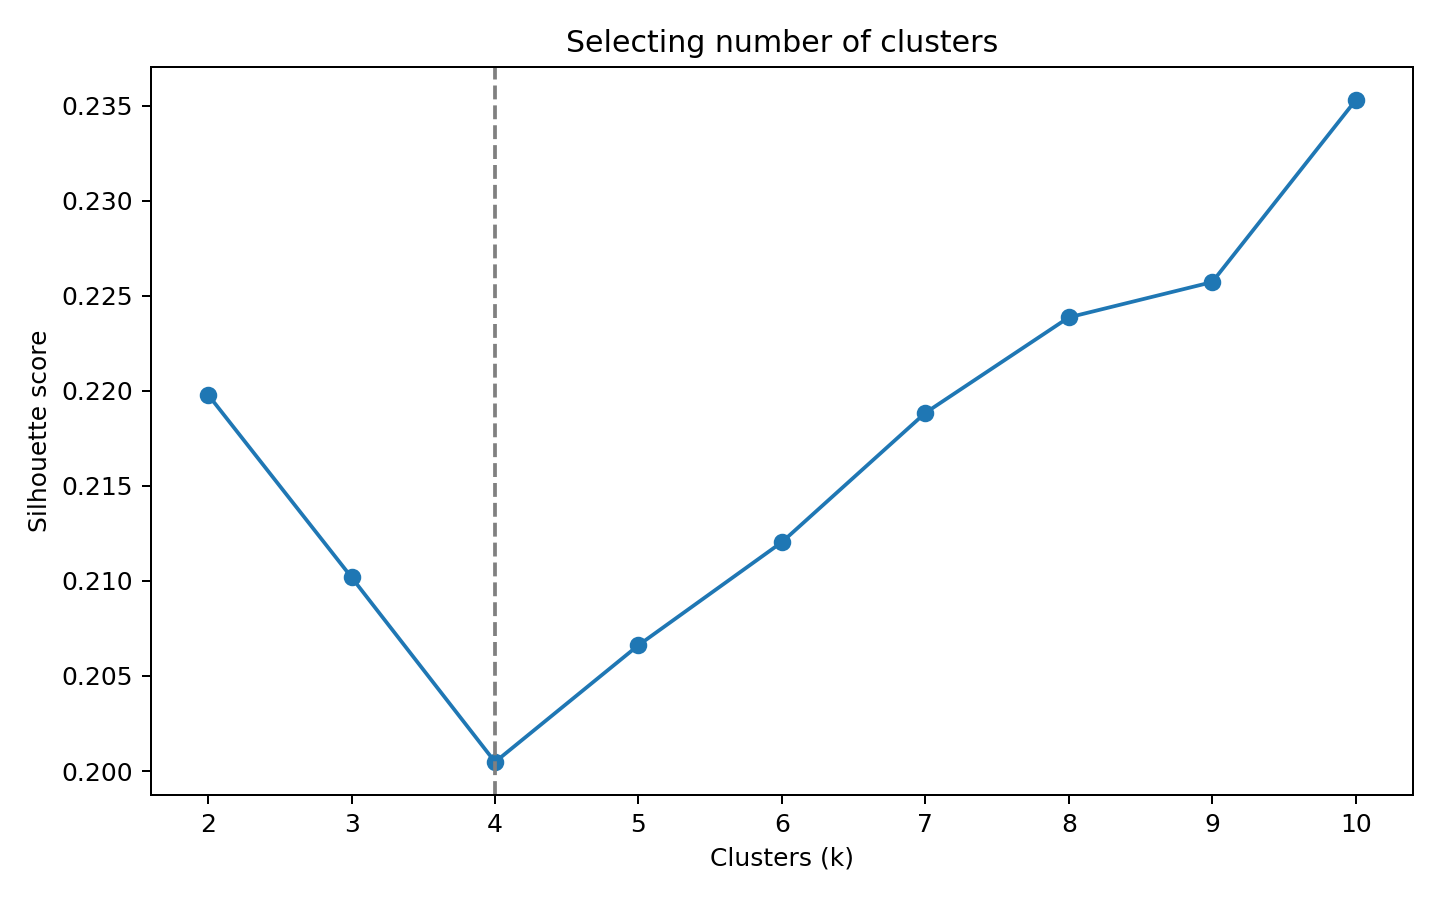

In [ ]:
metric_path = OUT / "cluster_metrics.csv"
if metric_path.exists():
    metrics = pd.read_csv(metric_path)
    display(metrics.round(3))
else:
    print("Missing", metric_path)
chart = OUT / "silhouette_scores.png"
if chart.exists(): display(Image(filename=str(chart)))

## 6. Customer segment profiles

Read the aggregate customer metrics. Each customer belongs to one cluster, but the cluster ID itself does not imply a ranking.

In [ ]:
profiles_path = OUT / "cluster_profiles.csv"
if profiles_path.exists():
    profiles = pd.read_csv(profiles_path)
    display(profiles.round(2))
else:
    print("Missing", profiles_path)

,cluster,customers,percentage,churn_rate_pct,mean_tenure,mean_MonthlyCharges
0,0,1693,24.04,24.51,10.44,31.72
1,1,1944,27.60,15.84,58.50,93.25
2,2,2245,31.88,48.60,14.80,80.58
3,3,1161,16.48,4.74,54.59,34.63


### Interpretation of the four segments

| Cluster | Descriptive name | Customers | Observed churn |
|---|---|---:|---:|
| 0 | Newer, lower-spending | 1,693 | 24.51% |
| 1 | Established, higher-spending | 1,944 | 15.84% |
| 2 | Newer, higher-spending | 2,245 | **48.60%** |
| 3 | Established, lower-spending | 1,161 | 4.74% |

Values come from the analysed **7,043-customer dataset**. They are descriptive, not evidence that tenure or higher charges *cause* churn.

## 7. Visualisations

The PCA plot provides a two-dimensional projection, which does not preserve all distances from the full transformed feature space. The churn chart compares **observed churn rates** after clustering.

### K-means cluster view (PCA projection)

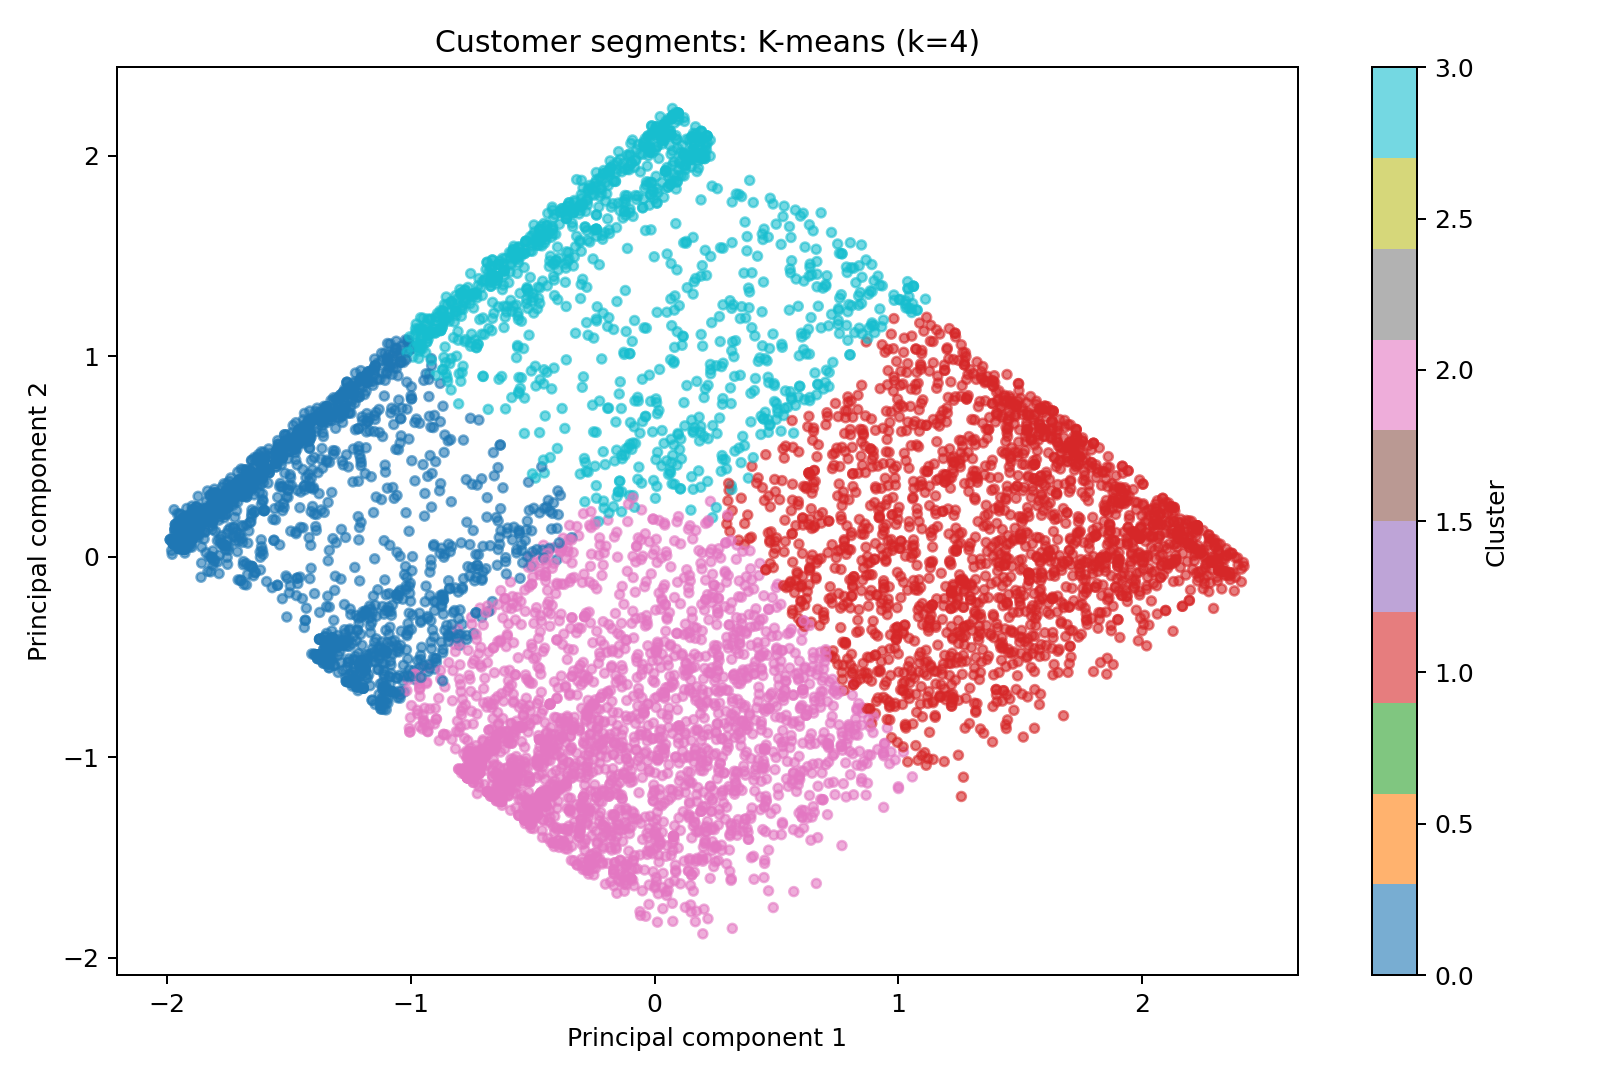

### Customers per cluster

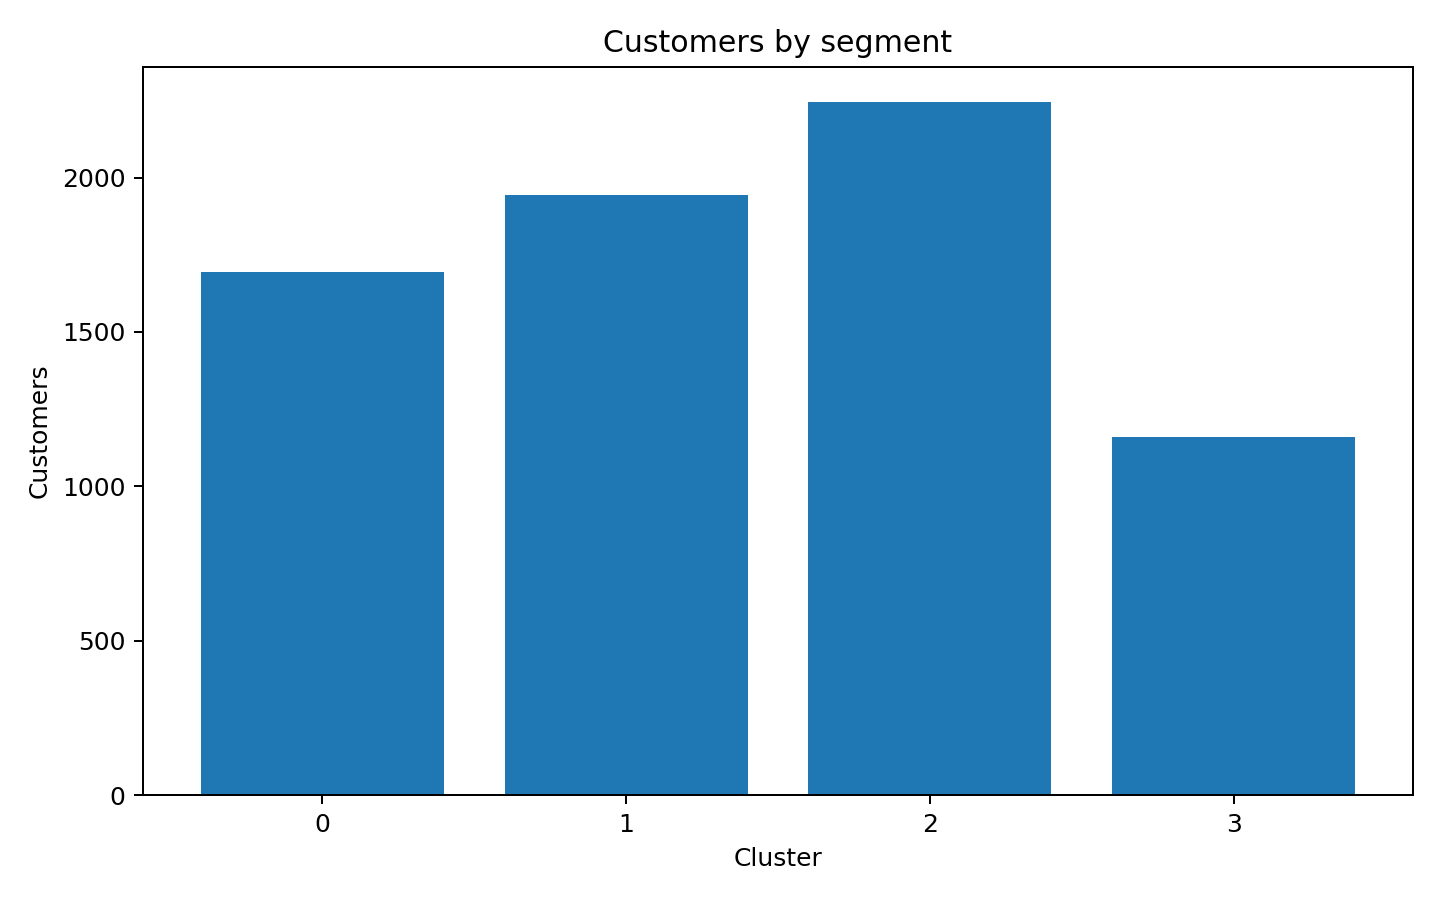

### Observed churn by cluster

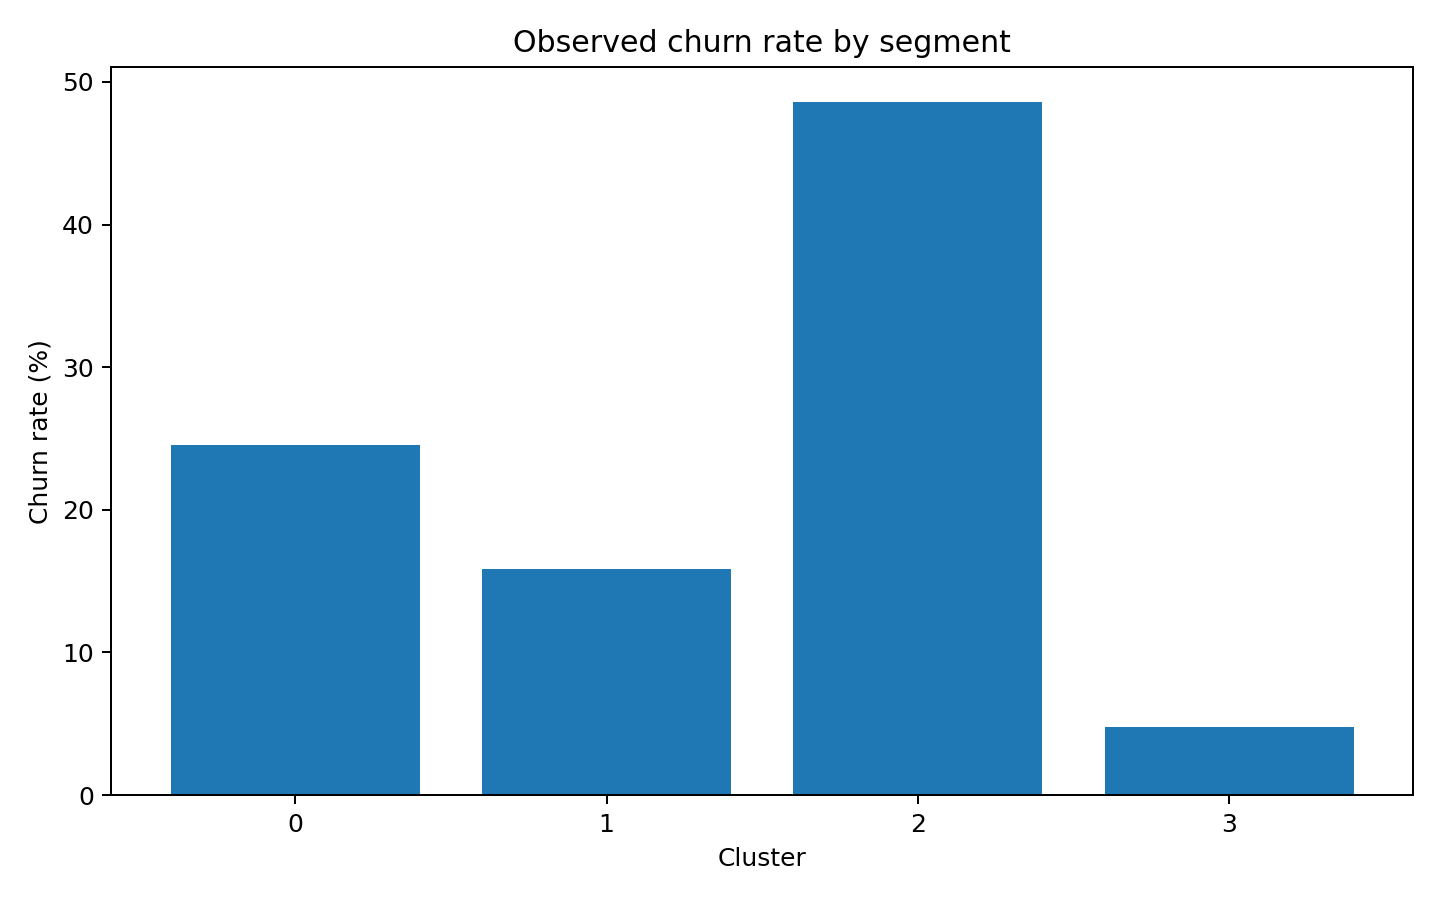

In [ ]:
for name, caption in [
    ("clusters_pca.png", "K-means cluster view (PCA projection)"),
    ("cluster_sizes.png", "Customers per cluster"),
    ("churn_by_cluster.png", "Observed churn by cluster")]:
    path = OUT / name
    display(Markdown(f"### {caption}"))
    if path.exists(): display(Image(filename=str(path)))
    else: print("Missing chart:", path)

## 8. Business findings and recommendations

**Primary retention hypothesis:** Cluster 2 combines shorter tenure and higher spending, with the highest observed churn (**48.60%**). Explore onboarding friction, service value, and early contract experience as possible research questions, then test targeted interventions before rollout.

**Established customers:** Cluster 3's observed churn (**4.74%**) is considerably lower. Examine which service or contract attributes are common in this group, without assuming causality.

**Suggested next steps:**

1. Review contract types and internet-service mixes by cluster.
2. Validate cluster stability across preprocessing choices and alternative k values.
3. Design a controlled retention experiment for the highest-churn segment.
4. Compare results with the team's predictive churn model — clustering is **not** a churn prediction accuracy score.

**Limitations:** Modest silhouette separation, possible sensitivity to one-hot encoding and scaling, observational data, no causal conclusions, and two-dimensional PCA visualisation. Customer identifiers and row-level records should not be published without explicit permission.

## 9. Project files and reproducibility

- `clustering.py` — reproducible analysis script.
- `requirements.txt` — dependencies.
- `outputs/cluster_metrics.csv` — model selection diagnostics.
- `outputs/cluster_profiles.csv` and `outputs/categorical_profiles.csv` — aggregated cluster profiles.
- `outputs/*.png` — charts.
- `README.md` — public project overview.

The **raw CSV is not included** in the public repository. To rerun from the root folder after placing an authorised dataset in `data/`, execute:

```bash
pip install -r requirements.txt
python clustering.py --input data/Dataset_ATS_v2.csv --out outputs --clusters 4
```

**Individual ACS contribution:** Document the analysis and customer-retention interpretation in your own words, and coordinate feature and preprocessing choices with your teammates.